Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (4.1.1-2.1build1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr-por is already the newest version (1:4.00~git30-7274cfa-1.1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
Selecione a imagem JPG:


Saving 20260511204204.jpg to 20260511204204 (3).jpg
Arquivo carregado: 20260511204204 (3).jpg


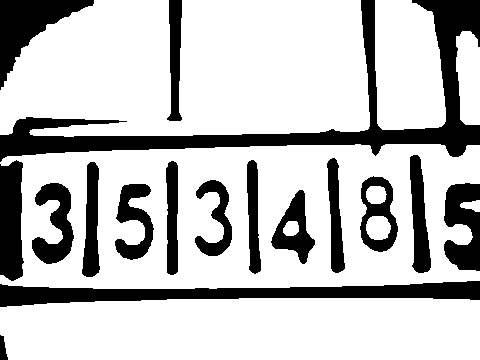


── Texto extraído ──────────────────────────────────


── Palavras detectadas com nível de confiança ──────
       text  conf  left  top  width  height
         F1    15     0    0     62      40
flslalalals    20     0   40    160      63

Texto salvo em: 20260511204204 (3)_ocr.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# Tesseract OCR no Google Colab
# ============================================================

# ── CÉLULA 1: Instalação das dependências ──────────────────
!apt-get install -y tesseract-ocr          # Engine principal
!apt-get install -y tesseract-ocr-por      # Pacote de idioma: Português
!pip install pytesseract Pillow            # Biblioteca Python + imagem


# ── CÉLULA 2: Upload da imagem ─────────────────────────────
from google.colab import files

print("Selecione a imagem JPG:")
uploaded = files.upload()

# Pega o nome do arquivo enviado
image_filename = list(uploaded.keys())[0]
print(f"Arquivo carregado: {image_filename}")


# ── CÉLULA 3: Executar o OCR ───────────────────────────────
import pytesseract
from PIL import Image, ImageFilter, ImageEnhance
import cv2
import numpy as np

image = Image.open(image_filename)

# ── Pré-processamento base ─────────────────────────────────
img_gray = image.convert("L")
largura, altura = img_gray.size
img_gray = img_gray.resize((largura * 3, altura * 3), Image.LANCZOS)
img_contraste = ImageEnhance.Contrast(img_gray).enhance(3.0)
img_np = np.array(img_contraste)

_, img_bin = cv2.threshold(img_np, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# ── Detecta se fundo é preto e inverte se necessário ───────
if img_bin.mean() < 127:
    img_bin = cv2.bitwise_not(img_bin)

# ── Crop automático: pega só a linha dos dígitos ───────────
# Soma pixels brancos por linha e encontra a região mais densa
soma_linhas = img_bin.sum(axis=1)
threshold_linha = soma_linhas.max() * 0.3
linhas_ativas = np.where(soma_linhas > threshold_linha)[0]
y1, y2 = linhas_ativas[0], linhas_ativas[-1]

# Margem extra
y1 = max(0, y1 - 10)
y2 = min(img_bin.shape[0], y2 + 10)
img_crop = img_bin[y1:y2, :]

# ── Dilata horizontalmente para preencher buracos ──────────
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 1))
img_dilat = cv2.dilate(img_crop, kernel, iterations=2)

# ── Exibe resultado ────────────────────────────────────────
display(Image.fromarray(img_dilat))

# ── OCR apenas com números ─────────────────────────────────
config = "--psm 7 -c tessedit_char_whitelist=0123456789"
texto = pytesseract.image_to_string(Image.fromarray(img_dilat), config=config)

print("\n── Texto extraído ──────────────────────────────────")
print(texto.strip())


# ── CÉLULA 4 (opcional): Detalhes por palavra ──────────────
import pandas as pd

dados = pytesseract.image_to_data(image, lang="por", output_type=pytesseract.Output.DATAFRAME)

# Filtra apenas palavras com confiança > 0
dados_filtrados = dados[dados["conf"] > 0][["text", "conf", "left", "top", "width", "height"]]
dados_filtrados = dados_filtrados.reset_index(drop=True)

print("\n── Palavras detectadas com nível de confiança ──────")
print(dados_filtrados.to_string(index=False))


# ── CÉLULA 5 (opcional): Salvar resultado em .txt ──────────
output_file = image_filename.replace(".jpg", "_ocr.txt").replace(".jpeg", "_ocr.txt")

with open(output_file, "w", encoding="utf-8") as f:
    f.write(texto)

print(f"\nTexto salvo em: {output_file}")

# Faz o download do arquivo de resultado
files.download(output_file)

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (4.1.1-2.1build1).
tesseract-ocr-por is already the newest version (1:4.00~git30-7274cfa-1.1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
Selecione a imagem JPG:


Saving 20260511204204.jpg to 20260511204204 (5).jpg


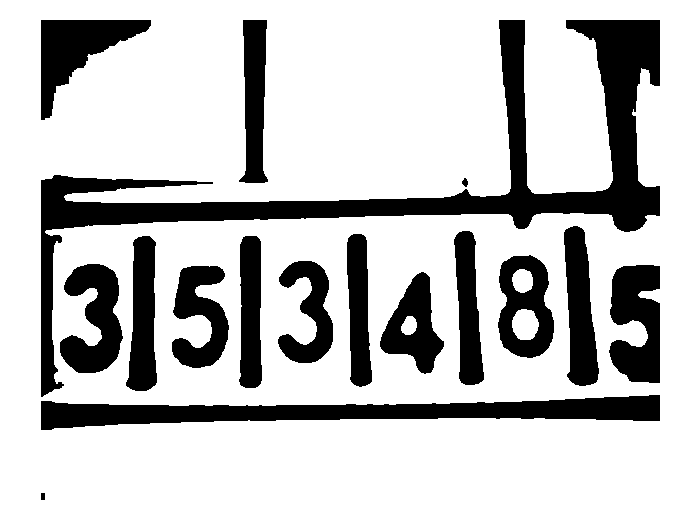


── Resultados brutos ───────────────────────────────
  '1581'  confiança: 67%

── Número lido: 1581 ─────────────────────


In [ ]:
# ── CÉLULA 1: Instalar dependências ───────────────────────
!apt-get install -y tesseract-ocr tesseract-ocr-por
!pip install pytesseract easyocr Pillow opencv-python-headless

# ── CÉLULA 2: Upload ───────────────────────────────────────
from google.colab import files
print("Selecione a imagem JPG:")
uploaded = files.upload()
image_filename = list(uploaded.keys())[0]

# ── CÉLULA 3: OCR com EasyOCR ──────────────────────────────
import easyocr
import cv2
import numpy as np
from PIL import Image, ImageEnhance
import re

image = Image.open(image_filename).convert("L")
w, h = image.size
image = image.resize((w * 4, h * 4), Image.LANCZOS)
image = ImageEnhance.Contrast(image).enhance(4.0)
img_np = np.array(image)

_, img_bin = cv2.threshold(img_np, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
if img_bin.mean() < 127:
    img_bin = cv2.bitwise_not(img_bin)

# ── Crop vertical: pega só a faixa dos dígitos ────────────
soma_linhas = img_bin.sum(axis=1)
ativas = np.where(soma_linhas > soma_linhas.max() * 0.35)[0]
y1, y2 = max(0, ativas[0] - 5), min(img_bin.shape[0], ativas[-1] + 5)
img_crop = img_bin[y1:y2, :]

# ── Crop horizontal: remove bordas laterais em branco/preto
soma_cols = img_crop.sum(axis=0)
ativas_col = np.where(soma_cols > soma_cols.max() * 0.1)[0]
x1, x2 = max(0, ativas_col[0] - 5), min(img_crop.shape[1], ativas_col[-1] + 5)
img_crop = img_crop[: , x1:x2]

# ── Remove barras verticais finas (separadores) ───────────
# Encontra colunas quase totalmente pretas (barras)
soma_cols2 = (img_crop == 0).sum(axis=0)
altura_crop = img_crop.shape[0]
colunas_barra = soma_cols2 > (altura_crop * 0.75)

# Pinta essas colunas de branco
img_sem_barras = img_crop.copy()
img_sem_barras[:, colunas_barra] = 255

# ── Morfologia: fecha buracos nos dígitos ─────────────────
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
img_final = cv2.morphologyEx(img_sem_barras, cv2.MORPH_CLOSE, kernel)

# Adiciona padding branco ao redor
img_final = cv2.copyMakeBorder(img_final, 20, 20, 20, 20,
                                cv2.BORDER_CONSTANT, value=255)

display(Image.fromarray(img_final))

# ── EasyOCR ───────────────────────────────────────────────
reader = easyocr.Reader(['en'], gpu=False)
resultados = reader.readtext(img_final, allowlist='0123456789',
                              detail=1, paragraph=False,
                              width_ths=0.3, ycenter_ths=0.8)

print("\n── Resultados brutos ───────────────────────────────")
for (bbox, texto, conf) in resultados:
    print(f"  '{texto}'  confiança: {conf:.0%}")

resultados_ord = sorted(resultados, key=lambda x: x[0][0][0])
numero_final = ''.join(re.sub(r'\D', '', r[1]) for r in resultados_ord)
print(f"\n── Número lido: {numero_final} ─────────────────────")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (4.1.1-2.1build1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
Selecione a imagem JPG do medidor:


Saving 20260511204204.jpg to 20260511204204 (7).jpg
Arquivo carregado: 20260511204204 (7).jpg


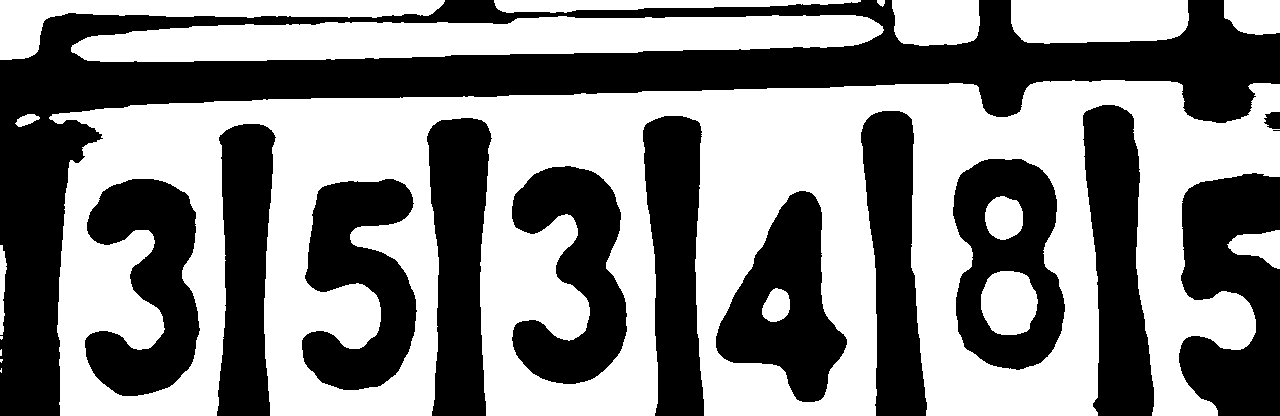


Dígitos encontrados: 6
  Dígito 1: '3'
  Dígito 2: '5'
  Dígito 3: '3'
  Dígito 4: '4'
  Dígito 5: '8'
  Dígito 6: '5'

─────────────────────────────────────────────
  LEITURA DO MEDIDOR: 353485
─────────────────────────────────────────────


In [ ]:
# ============================================================
# OCR para Medidor Analógico com Display de Rolinhos
# ============================================================

# ── CÉLULA 1: Instalação ───────────────────────────────────
!apt-get install -y tesseract-ocr
!pip install pytesseract opencv-python-headless Pillow


# ── CÉLULA 2: Upload da imagem ─────────────────────────────
from google.colab import files

print("Selecione a imagem JPG do medidor:")
uploaded = files.upload()
image_filename = list(uploaded.keys())[0]
print(f"Arquivo carregado: {image_filename}")


# ── CÉLULA 3: OCR por segmentação de dígitos ───────────────
import cv2
import numpy as np
from PIL import Image
import pytesseract

# --- Configurações (ajuste se necessário) ---
CROP_Y1      = 38    # linha inicial da faixa dos dígitos (em pixels da imagem original)
CROP_Y2      = 90    # linha final
CROP_X1      = 0    # coluna inicial
CROP_X2      = 160   # coluna final (use a largura total da imagem)
UPSCALE      = 8     # fator de ampliação
MIN_AREA     = 2000  # área mínima de um dígito (em pixels após upscale)
MIN_HEIGHT   = 80    # altura mínima de um dígito (em pixels após upscale)

# --- Carregamento e pré-processamento ---
img  = cv2.imread(image_filename)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Recorta a região dos dígitos
region = gray[CROP_Y1:CROP_Y2, CROP_X1:CROP_X2]

# Amplia e melhora contraste
up     = cv2.resize(region, (region.shape[1]*UPSCALE, region.shape[0]*UPSCALE),
                    interpolation=cv2.INTER_LANCZOS4)
clahe  = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(4, 4))
up_enh = clahe.apply(up)

# Binariza (preto e branco puro)
_, binarized = cv2.threshold(up_enh, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
if binarized.mean() < 127:          # garante fundo branco
    binarized = cv2.bitwise_not(binarized)

# Exibe a imagem pré-processada
display(Image.fromarray(binarized))

# --- Segmentação por componentes conectados ---
H, W       = binarized.shape
digit_mask = (binarized == 0).astype(np.uint8) * 255   # pixels escuros = dígitos
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(digit_mask, connectivity=8)

# Filtra apenas componentes com formato de dígito
candidates = []
for i in range(1, num_labels):
    area   = stats[i, cv2.CC_STAT_AREA]
    w_cc   = stats[i, cv2.CC_STAT_WIDTH]
    h_cc   = stats[i, cv2.CC_STAT_HEIGHT]
    x_cc   = stats[i, cv2.CC_STAT_LEFT]
    y_cc   = stats[i, cv2.CC_STAT_TOP]
    aspect = w_cc / h_cc if h_cc > 0 else 0

    if area >= MIN_AREA and h_cc >= MIN_HEIGHT and 0.3 <= aspect <= 2.0:
        candidates.append((x_cc, i, area, w_cc, h_cc, y_cc))

# Ordena da esquerda para a direita
candidates.sort(key=lambda c: c[0])
print(f"\nDígitos encontrados: {len(candidates)}")

# --- Leitura individual de cada dígito ---
digits_read = []
for idx, (x_pos, comp_id, area, w_cc, h_cc, y_pos) in enumerate(candidates):
    pad = 20
    x1 = max(0, x_pos - pad)
    y1 = max(0, y_pos - pad)
    x2 = min(W, x_pos + w_cc + pad)
    y2 = min(H, y_pos + h_cc + pad)

    digit_img    = binarized[y1:y2, x1:x2]
    digit_padded = cv2.copyMakeBorder(digit_img, 30, 30, 30, 30,
                                       cv2.BORDER_CONSTANT, value=255)
    pil_digit = Image.fromarray(digit_padded)

    result = pytesseract.image_to_string(
        pil_digit,
        config="--psm 10 -c tessedit_char_whitelist=0123456789"
    ).strip()
    digit_clean = ''.join(c for c in result if c.isdigit())
    print(f"  Dígito {idx+1}: '{digit_clean}'")
    digits_read.append(digit_clean)

# --- Resultado final ---
leitura_final = ''.join(digits_read)
print(f"\n{'─'*45}")
print(f"  LEITURA DO MEDIDOR: {leitura_final}")
print(f"{'─'*45}")